In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

In [ ]:
uploaded = files.upload()
uploaded_names = list(uploaded.keys())

def find_uploaded_image(keyword, fallback_index):
  matches = [
      name for name in uploaded_names if keyword.lower() in name.lower()
  ]

  if matches:
    return '/content/' + matches[0]

  if fallback_index is not None:
    return '/content/' + uploaded_names[fallback_index]
  raise ValueError(f'No Image Found For Keyword: {keyword}')

bright_path = find_uploaded_image('bright', 0)
dark_path = find_uploaded_image('dark', 1)

bright = cv2.imread(bright_path)
dark = cv2.imread(dark_path)

print(bright.shape)
print(dark.shape)

Saving cube-bright.png to cube-bright (1).png
Saving cube-dark.png to cube-dark (1).png
(229, 224, 3)
(232, 229, 3)


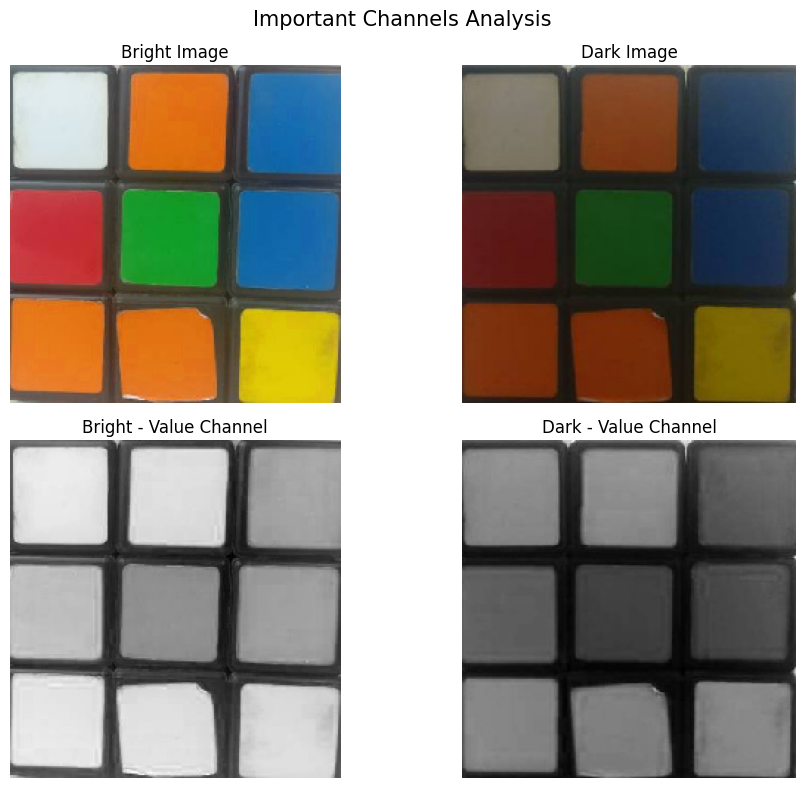

In [16]:
def show_important_channels_only(bright, dark, bright_hsv=None, dark_hsv=None):

    if bright_hsv is None:
        bright_hsv = cv2.cvtColor(bright, cv2.COLOR_BGR2HSV)

    if dark_hsv is None:
        dark_hsv = cv2.cvtColor(dark, cv2.COLOR_BGR2HSV)

    plt.figure(figsize=(10, 8))

    plt.subplot(2, 2, 1)
    plt.imshow(cv2.cvtColor(bright, cv2.COLOR_BGR2RGB))
    plt.title('Bright Image')
    plt.axis('off')

    plt.subplot(2, 2, 2)
    plt.imshow(cv2.cvtColor(dark, cv2.COLOR_BGR2RGB))
    plt.title('Dark Image')
    plt.axis('off')

    plt.subplot(2, 2, 3)
    plt.imshow(bright_hsv[:, :, 2], cmap='gray')
    plt.title('Bright - Value Channel')
    plt.axis('off')

    plt.subplot(2, 2, 4)
    plt.imshow(dark_hsv[:, :, 2], cmap='gray')
    plt.title('Dark - Value Channel')
    plt.axis('off')

    plt.suptitle('Important Channels Analysis', fontsize=15)
    plt.tight_layout()
    plt.show()

show_important_channels_only(bright, dark)

HSV Value: bright_mean=168.43, dark_mean=86.79
LAB L: bright_mean=132.98, dark_mean=67.56
YCrCb Y: bright_mean=117.40, dark_mean=60.48


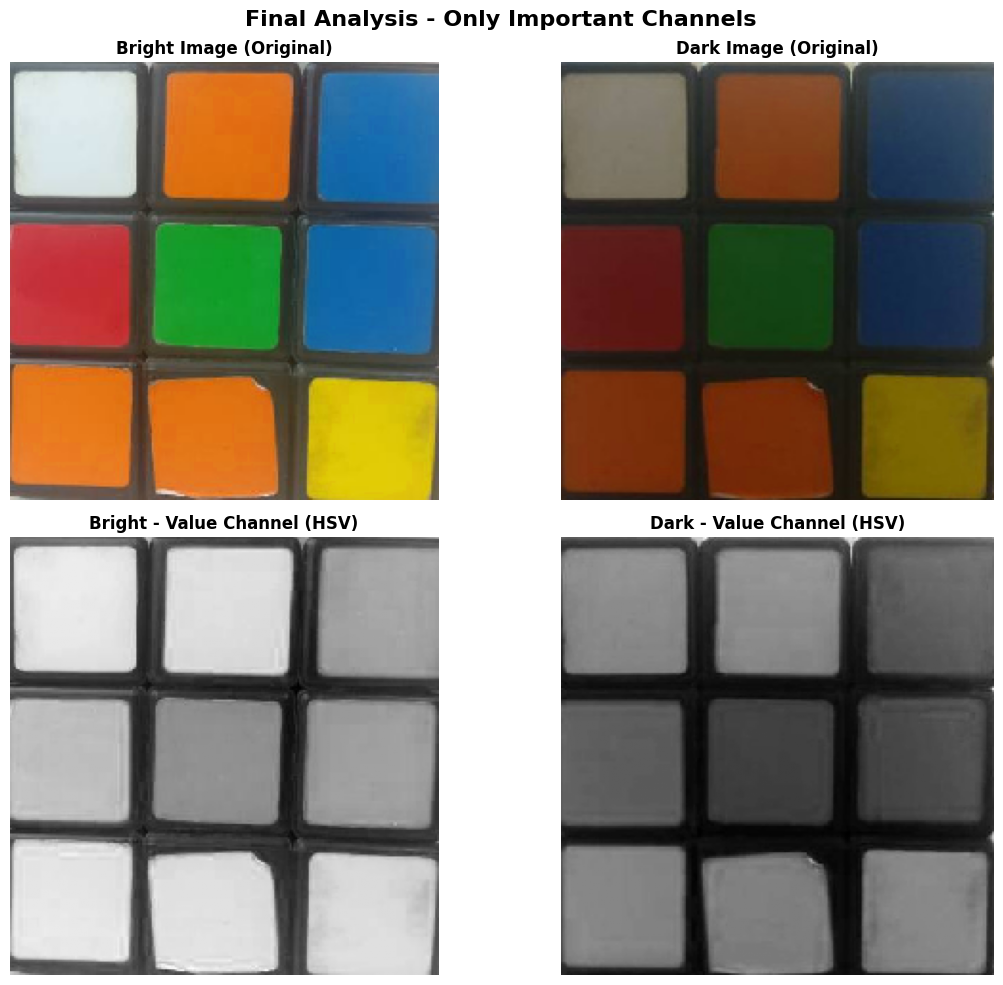

In [13]:
bright_hsv = cv2.cvtColor(bright, cv2.COLOR_BGR2HSV)
dark_hsv = cv2.cvtColor(dark, cv2.COLOR_BGR2HSV)

bright_lab = cv2.cvtColor(bright, cv2.COLOR_BGR2LAB)
dark_lab = cv2.cvtColor(dark, cv2.COLOR_BGR2LAB)

bright_ycrcb = cv2.cvtColor(bright, cv2.COLOR_BGR2YCrCb)
dark_ycrcb = cv2.cvtColor(dark, cv2.COLOR_BGR2YCrCb)

brightness_channels = {
    'HSV Value': (bright_hsv[:, :, 2], dark_hsv[:, :, 2]),
    'LAB L': (bright_lab[:, :, 0], dark_lab[:, :, 0]),
    'YCrCb Y': (bright_ycrcb[:, :, 0], dark_ycrcb[:, :, 0]),
}

for channel_name, (bright_channel, dark_channel) in brightness_channels.items():
    print(
        f'{channel_name}: '
        f'bright_mean={bright_channel.mean():.2f}, '
        f'dark_mean={dark_channel.mean():.2f}'
    )

def show_final_important_channels(bright, dark, bright_hsv, dark_hsv):

    plt.figure(figsize=(12, 10))

    plt.subplot(2, 2, 1)
    plt.imshow(cv2.cvtColor(bright, cv2.COLOR_BGR2RGB))
    plt.title('Bright Image (Original)', fontsize=12, fontweight='bold')
    plt.axis('off')

    plt.subplot(2, 2, 2)
    plt.imshow(cv2.cvtColor(dark, cv2.COLOR_BGR2RGB))
    plt.title('Dark Image (Original)', fontsize=12, fontweight='bold')
    plt.axis('off')

    plt.subplot(2, 2, 3)
    plt.imshow(bright_hsv[:, :, 2], cmap='gray')
    plt.title('Bright - Value Channel (HSV)', fontsize=12, fontweight='bold')
    plt.axis('off')

    plt.subplot(2, 2, 4)
    plt.imshow(dark_hsv[:, :, 2], cmap='gray')
    plt.title('Dark - Value Channel (HSV)', fontsize=12, fontweight='bold')
    plt.axis('off')

    plt.suptitle('Final Analysis - Only Important Channels', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

show_final_important_channels(bright, dark, bright_hsv, dark_hsv)